# Computational Lab 4: CO₂ — Normal Modes and Why It Absorbs Infrared Light
*CHEM 3376 — Physical Chemistry Laboratory: Data Analysis & Computation*

CO₂ is only 0.04 % of the atmosphere, yet it is the main long-lived greenhouse gas. It has no permanent dipole moment, and it
is linear and symmetric like O₂. Why does it absorb infrared light when O₂ does not?

A molecule with $N$ atoms has $3N$ coordinates. For a **linear** molecule, 3 are translations and 2 are rotations, leaving
$3N-5 = 4$ **vibrations** for CO₂. In the **harmonic approximation** the energy near the minimum is

$$E \approx E_0 + \tfrac12 \sum_{ij} H_{ij}\, \Delta x_i\, \Delta x_j, \qquad H_{ij} = \frac{\partial^2 E}{\partial x_i\,\partial x_j}.$$

$H$ is the **Hessian** (force-constant matrix). The vibrations that move independently are the **normal modes**: the
eigenvectors of the *mass-weighted* Hessian $H_{ij}/\sqrt{m_i m_j}$, whose eigenvalues are $\omega^2$. In this lab you will:

1. find the equilibrium geometry of CO₂ with DFT (B3LYP/def2-SVP);
2. compute the Hessian, and check one element yourself by finite differences;
3. find the normal modes and frequencies, and **watch each mode in 3-D**;
4. compute each mode's **IR intensity** from the change of the dipole;
5. place the spectrum under the Earth's thermal emission: **the greenhouse connection**.

Your results are saved for Labs 5 and 6.

<br>**<center>Learning Goals**

|Area|Concept|
|---|---|
|Vibrations|The Hessian; mass weighting; normal modes and normal coordinates; 3N − 5 and 3N − 6|
|Spectroscopy|IR intensities from dipole derivatives; selection rules from symmetry; IR-active and IR-inactive modes|
|Symmetry|The inversion centre of CO₂; why the symmetric stretch is IR-inactive; degenerate bends|
|Climate|Black-body emission of the Earth; why the 15 µm bend of CO₂ matters for the greenhouse effect|
|Numerical methods|Optimisation in one variable; analytic vs finite-difference derivatives; eigenvalue problems|
|Python|`reshape` and `transpose` of arrays; `np.outer`; `np.linalg.eigh`; `lambda` functions|

---
## 📄 Abstract

<div style="border:2px solid #1f4e79; border-radius:8px; padding:10px 14px; background:#f3f7fb; color:#1a1a1a;">

**Write this section last**, after you have finished the lab. Your abstract goes in the cell below, replacing `ANSWER`.

In **150–250 words**, as in a journal article: state the purpose; name the method (B3LYP/def2-SVP, PySCF, analytic Hessian,
finite-difference dipole derivatives); give your **key numbers** with experiment beside them (r_e, the four harmonic wavenumbers
and their IR intensities); explain which modes absorb and why; and finish with the climate connection.
</div>

**Sample answer (instructor version).** The harmonic vibrational spectrum of carbon dioxide was computed with density functional theory (B3LYP/def2-SVP, PySCF) to explain why CO₂, a linear molecule without a permanent dipole moment, absorbs infrared light while O₂ does not. The optimised C=O bond length is 1.163 Å (experiment 1.160 Å). Diagonalising the mass-weighted analytic Hessian gives five near-zero eigenvalues (three translations and two rotations) and four vibrations: the doubly degenerate bend at 654 cm⁻¹, the symmetric stretch at 1389 cm⁻¹ and the asymmetric stretch at 2467 cm⁻¹ (experiment 667, ≈1333 and 2349 cm⁻¹). A finite-difference second derivative reproduces the analytic Hessian element for carbon to 0.5 %. IR intensities from central differences of the dipole along each normal coordinate are 2 × 33 km mol⁻¹ for the bend, 0 for the symmetric stretch and 614 km mol⁻¹ for the asymmetric stretch (experiment 2 × 24 and 548 km mol⁻¹). The symmetric stretch keeps the inversion centre and so never develops a dipole; the bend and asymmetric stretch break it, and the dipole oscillates. The bend lies under the peak of the Earth's 288 K thermal emission (near 560 cm⁻¹), so it is this vibration, not the more intense asymmetric stretch, that makes CO₂ a greenhouse gas.

---

## ⚙️ Initialization — DO NOT EDIT
The next two cells load the course tools (auto-checks, quizzes, styling) and record the lab version. **Do not change them** — with one exception:

👁️ **Accessible view (optional):** set `ACCESSIBLE_VIEW = True` in the cell below for larger, more readable text and colorblind-safe plots. You can switch back any time by setting it to `False` and re-running the cell (then *Kernel → Restart* to clear the text styling).

👉 **Run the cell below first** (Shift+Enter) before anything else in this lab.

In [1]:
# 🔧 Run this cell first! (Shift+Enter)
ACCESSIBLE_VIEW = True     # True = larger text and colorblind-safe plots

import sys, os
for _up in ("..", os.path.join("..", ".."), os.path.join("..", "..", "..")):
    _shared = os.path.abspath(os.path.join(os.getcwd(), _up, "shared-public"))
    if os.path.isdir(_shared):
        sys.path.insert(0, _shared)
        break
if ACCESSIBLE_VIEW:
    from init_access import *
else:
    from init import *

In [2]:
# 🔖 Lab version — do not edit. Used by the automated checks below.
ver = '2026Comp04V1'

### 🧰 Standard imports
`numpy`, `matplotlib`, a one-variable minimiser from SciPy, PySCF's `gto` and `dft`, and `labkit` (constants, masses and the
3-D viewer). The last lines load this lab's **answer checks**: after each question, run `lab.check(...)`.

In [3]:
# Standard imports for this lab
import time
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from pyscf import gto, dft
for _up in ("..", os.path.join("..", "..")):          # labkit is in comp_chem/, the folder above this lab
    if os.path.isdir(os.path.join(_up, "labkit")):
        sys.path.insert(0, os.path.abspath(_up))
        break
import labkit as lk

# Answer checks for this lab: the checker (pchem_check.py) and the answer key (answers_comp04.json) are in this folder
from pchem_check import Checker
lab = Checker('comp04', 'answers_comp04.json')

Now run the cell below to enter your name.

In [4]:
# Enter your name as a string, e.g. name = 'Linus Pauling'
name = 'Instructor'

**Just run the cell below.** It defines the atoms (O, C, O, with masses in amu), a function `co2_mf(X)` that runs B3LYP on
CO₂ at a geometry `X` (a 3 × 3 array: one row of x, y, z in Å per atom) and returns the converged PySCF object, and a function
`linear_co2(r)` that builds the linear, symmetric geometry with both C=O bonds equal to `r`.

In [5]:
# Just run this cell: atoms, masses, and the DFT calculation
symbols = ["O", "C", "O"]
masses = np.array([lk.MASS[s] for s in symbols])         # amu
HARTREE_TO_EV, BOHR_TO_ANG = lk.HARTREE_TO_EV, lk.BOHR_TO_ANG

def co2_mf(X, basis="def2-svp", xc="b3lyp"):
    """Run B3LYP on CO2 at Cartesian geometry X (3 x 3, Å); return the converged PySCF object (energy: .e_tot, hartree)."""
    mol = gto.M(atom=[[s, tuple(x)] for s, x in zip(symbols, X)], basis=basis, verbose=0)
    mf = dft.RKS(mol); mf.xc = xc
    mf.kernel()
    return mf

def linear_co2(r):
    """Linear CO2 along z with both C=O bonds equal to r (Å): O at -r, C at 0, O at +r."""
    return np.array([[0, 0, -r], [0, 0, 0], [0, 0, r]], float)

print(linear_co2(1.16))

[[ 0.    0.   -1.16]
 [ 0.    0.    0.  ]
 [ 0.    0.    1.16]]


## 1. Equilibrium Geometry

### <font color=blue> **Question 1.1.** </font>
By symmetry the minimum is linear with two equal C=O bonds, so we only need to minimise the energy over **one** bond length.
Complete `energy_of_r(r)`, which returns the B3LYP energy (hartree) of linear CO₂ with bond length `r`. The cell then calls
`scipy.optimize.minimize_scalar` to find the bond length `r_e` that minimises it (about 15 s). Experiment: 1.1600 Å.

🐍 **Python tip — passing a function to a function.** `minimize_scalar(energy_of_r, ...)` hands your function to SciPy, which
calls it at the bond lengths it chooses until it finds the minimum. You did the same in Lab 1 with `h_atom_energy`.

<details><summary>💡 <b>Hint</b></summary>

Build the geometry and run the calculation: `return co2_mf(linear_co2(r)).e_tot`.
</details>

In [6]:
def energy_of_r(r):
    """B3LYP/def2-SVP energy (hartree) of linear, symmetric CO2 with C=O bond length r (Å)."""
    return co2_mf(linear_co2(r)).e_tot
t = time.time()
res = minimize_scalar(energy_of_r, bounds=(1.10, 1.22), method="bounded", options={"xatol": 1e-5})
r_e = res.x
X0 = linear_co2(r_e)
print(f"r_e(C=O) = {r_e:.4f} Å   ({time.time() - t:.0f} s)   experiment 1.1600 Å")
lk.show_molecule(symbols, X0, labels=True)

r_e(C=O) = 1.1631 Å   (2 s)   experiment 1.1600 Å


In [7]:
lab.check('1.1')

## 2. The Hessian

### 2.1 Analytic second derivatives
PySCF computes the Hessian analytically: `mf.Hessian().kernel()` returns an array `H4` of shape `(3, 3, 3, 3)` in
**hartree/bohr²**, where element `H4[a, b, i, j]` is $\partial^2E/\partial x_{a,i}\,\partial x_{b,j}$ for atoms `a`, `b` and
Cartesian directions `i`, `j`.

For the normal-mode analysis we want a $9\times 9$ matrix whose rows and columns run over the 9 coordinates in the order
(O₁x, O₁y, O₁z, Cx, Cy, Cz, O₂x, O₂y, O₂z), i.e. **(atom, direction)**. That means putting the axes in the order
`[a, i, b, j]` before reshaping: `H4.transpose(0, 2, 1, 3).reshape(9, 9)`.

### <font color=blue> **Question 2.1.** </font>
Complete the line that reorders `H4` into the 9 × 9 matrix `H` and **converts it to eV/Å²**.
Element `H[5, 5]` is then $\partial^2E/\partial z_C^2$, the curvature for moving the carbon atom along the bond.

🐍 **Python tip — `transpose` and `reshape`.** `A.transpose(0, 2, 1, 3)` swaps the 2nd and 3rd axes of a 4-index array;
`.reshape(9, 9)` then reads the numbers in order and lays them out as 9 rows of 9.

<details><summary>💡 <b>Hint</b></summary>

Energy hartree → eV, and each of the two lengths bohr → Å:
`H = H4.transpose(0, 2, 1, 3).reshape(9, 9) * HARTREE_TO_EV / BOHR_TO_ANG**2`.
</details>

In [8]:
t = time.time()
mf0 = co2_mf(X0)
H4 = mf0.Hessian().kernel()
print(f"analytic Hessian: shape {H4.shape} ({time.time() - t:.0f} s)")
H = H4.transpose(0, 2, 1, 3).reshape(9, 9) * HARTREE_TO_EV / BOHR_TO_ANG**2
print("symmetric:", np.allclose(H, H.T, atol=1e-6))
print(f"H[C_z, C_z] = {H[5, 5]:.2f} eV/Å²")

analytic Hessian: shape (3, 3, 3, 3) (2 s)
symmetric: True
H[C_z, C_z] = 195.29 eV/Å²


In [9]:
lab.check('2.1')

### <font color=blue> **Question 2.2.** </font>
**Check one element yourself.** Displace the carbon atom along z by $\pm h$ with $h$ = 0.005 Å, and compute the
finite-difference second derivative

$$ \frac{\partial^2 E}{\partial z_C^2} \approx \frac{E(+h) - 2E(0) + E(-h)}{h^2} $$

in eV/Å² (the energies are in hartree). Compare with `H[5, 5]`. Expect agreement to about 0.5 %: the DFT energy is
integrated on a grid of points that moves with the atoms, and PySCF's analytic Hessian leaves out that small grid-motion term,
while the finite difference includes it.

<details><summary>💡 <b>Hint</b></summary>

`fd = (Ep - 2 * E0 + Em) / h**2 * HARTREE_TO_EV`.
</details>

In [10]:
h = 0.005
dC = np.array([[0, 0, 0], [0, 0, h], [0, 0, 0]])     # move only the carbon, along z
Ep = co2_mf(X0 + dC).e_tot
Em = co2_mf(X0 - dC).e_tot
E0 = mf0.e_tot
fd = (Ep - 2 * E0 + Em) / h**2 * HARTREE_TO_EV
print(f"H[C_z, C_z]: analytic {H[5, 5]:.2f} eV/Å², finite difference {fd:.2f} eV/Å²")

H[C_z, C_z]: analytic 195.29 eV/Å², finite difference 196.18 eV/Å²


In [11]:
lab.check('2.2')

## 3. Normal Modes and Frequencies

### 3.1 Mass weighting
Newton's equations for small displacements, $m_i \ddot x_i = -\sum_j H_{ij} x_j$, become an eigenvalue problem when each
coordinate is scaled by $\sqrt{m_i}$. The **mass-weighted Hessian** is

$$ \tilde H_{ij} = \frac{H_{ij}}{\sqrt{m_i m_j}} , $$

its eigenvalues are $\lambda_k = \omega_k^2$, and its eigenvectors $\mathbf L_k$ are the normal modes
([Atkins, Topic 11D](https://global.oup.com/academic/product/atkins-physical-chemistry-9780198769866);
[Wilson, Decius & Cross](https://store.doverpublications.com/0486639411.html)). With $H$ in eV/Å² and $m$ in amu,
$\omega$ in rad/fs is $\sqrt{\lambda \times \texttt{lk.ACC}}$, and `lk.omega_to_wavenumber` converts to cm⁻¹.

### <font color=blue> **Question 3.1.** </font>
`m3` holds the mass of each of the 9 coordinates (each atom's mass three times). Complete the line that builds the
mass-weighted Hessian `Hmw`. The cell then diagonalises it and converts the eigenvalues to wavenumbers (negative
eigenvalues are shown as negative wavenumbers).

🐍 **Python tip — `np.outer`.** `np.outer(a, b)` is the matrix with elements `a[i] * b[j]`. So `np.sqrt(np.outer(m3, m3))`
holds $\sqrt{m_i m_j}$ for every pair of coordinates.

<details><summary>💡 <b>Hint</b></summary>

`Hmw = H / np.sqrt(np.outer(m3, m3))`.
</details>

In [12]:
m3 = np.repeat(masses, 3)                         # mass of each of the 9 coordinates
Hmw = H / np.sqrt(np.outer(m3, m3))
lam, L = np.linalg.eigh(Hmw)
wn_all = lk.omega_to_wavenumber(np.sign(lam) * np.sqrt(np.abs(lam) * lk.ACC))
print("all 9 eigenvalues as wavenumbers (cm⁻¹):", np.round(wn_all, 1))
wn = wn_all[5:]                                   # the four vibrations
print("vibrations (cm⁻¹):", np.round(wn, 1), "   experiment: 667, 667, ≈1333, 2349")

all 9 eigenvalues as wavenumbers (cm⁻¹): [  -20.9   -20.9   -18.    -18.     22.8   653.7   653.7  1389.   2466.9]
vibrations (cm⁻¹): [  653.7   653.7  1389.   2466.9]    experiment: 667, 667, ≈1333, 2349


In [13]:
lab.check('3.1')

**Just run the cell below** to watch each mode. The eigenvectors are in mass-weighted coordinates; dividing by $\sqrt{m}$ turns
them into the Cartesian displacement pattern `disp`. Drag to rotate, scroll to zoom.

In [14]:
# Just run this cell: the displacement pattern of each mode, and a 3-D animation of each
modes = L[:, 5:]                                   # mass-weighted eigenvectors, one column per mode
disp = modes / np.sqrt(m3)[:, None]                # Cartesian displacement pattern of each mode
for k in range(4):
    print(f"mode {k}: {wn[k]:7.1f} cm⁻¹   displacement (x, y, z for O, C, O):")
    print(np.round(disp[:, k].reshape(3, 3), 3))
    lk.animate_mode(symbols, X0, disp[:, k], amplitude=0.25)

mode 0:   653.7 cm⁻¹   displacement (x, y, z for O, C, O):
[[ 0.092  0.     0.   ]
 [-0.246 -0.001 -0.   ]
 [ 0.092  0.     0.   ]]
mode 1:   653.7 cm⁻¹   displacement (x, y, z for O, C, O):
[[ 0.    -0.092 -0.   ]
 [-0.001  0.246  0.   ]
 [ 0.    -0.092 -0.   ]]


mode 2:  1389.0 cm⁻¹   displacement (x, y, z for O, C, O):
[[ 0.     0.     0.177]
 [-0.    -0.    -0.   ]
 [ 0.     0.    -0.177]]
mode 3:  2466.9 cm⁻¹   displacement (x, y, z for O, C, O):
[[-0.    -0.     0.092]
 [ 0.     0.    -0.246]
 [-0.    -0.     0.092]]


### <font color=blue> **Question 3.2 Discussion.** </font>
<font color=green>

1. How many of the 9 eigenvalues are close to zero, and why? (They "should" be exactly zero; the DFT integration grid makes
   them a few cm⁻¹ instead.)
2. Name the four modes: symmetric stretch, asymmetric stretch, and the two bends. Why are there **two** bends with the same
   frequency, but only one of each stretch?
3. In the symmetric stretch, does the carbon atom move? In the asymmetric stretch, which atom moves most, and why?
</font>

---

**Sample answer (instructor version).** Five eigenvalues are near zero: three translations and two rotations of a linear molecule (rotation about the axis moves no nuclei), leaving 3N − 5 = 4 vibrations. Modes 0 and 1 (654 cm⁻¹) are the bend, in two perpendicular planes; they are degenerate because the molecule is cylindrically symmetric, so bending in x or in y costs the same energy. Mode 2 (1389 cm⁻¹) is the symmetric stretch, in which the two O atoms move out and in together and the carbon stays still; mode 3 (2467 cm⁻¹) is the asymmetric stretch, in which the light carbon atom moves most, against both oxygens, so that the centre of mass stays fixed.

---

In [15]:
lab.check('3.2d')

## 4. Infrared Intensities

### 4.1 Dipole derivatives
The IR intensity of mode $k$ is proportional to $|\partial\boldsymbol\mu/\partial Q_k|^2$, where $Q_k$ is the mass-weighted
normal coordinate. Move the molecule a small step along the mode, $\mathbf X_\pm = \mathbf X_0 \pm \delta\,\mathbf L_k/\sqrt{m}$,
and take a central difference:

$$\frac{\partial\boldsymbol\mu}{\partial Q_k} \approx \frac{\boldsymbol\mu(\mathbf X_+) - \boldsymbol\mu(\mathbf X_-)}{2\delta}.$$

With $\mu$ in D and $Q$ in Å·amu$^{1/2}$, the intensity in the usual units is
$A_k\,[\text{km/mol}] = 42.256\,|\partial\boldsymbol\mu/\partial Q_k|^2$, where $|\mathbf v|^2$ sums the squares of the x, y and z
components ([Atkins, Topic 11D](https://global.oup.com/academic/product/atkins-physical-chemistry-9780198769866)).

### <font color=blue> **Question 4.1.** </font>
Complete `ir_intensity(k, delta)`: the central difference `dmu` (a vector of 3 components) and the intensity in km/mol.
The cell computes all four (8 DFT calculations, about 10 s).

<details><summary>💡 <b>Hint</b></summary>

`dmu = (dipole(X0 + dX) - dipole(X0 - dX)) / (2 * delta)` and `return 42.256 * np.sum(dmu**2)`.
</details>

In [16]:
def dipole(X):
    """Dipole vector (debye) of CO2 at geometry X."""
    return co2_mf(X).dip_moment(unit="Debye", verbose=0)

def ir_intensity(k, delta=0.01):
    """IR intensity (km/mol) of normal mode k by a central finite difference of the dipole."""
    dX = (delta * disp[:, k]).reshape(3, 3)       # a step δ along mode k, as a 3 x 3 displacement
    dmu = (dipole(X0 + dX) - dipole(X0 - dX)) / (2 * delta)
    return 42.256 * np.sum(dmu**2)
t = time.time()
A = np.array([ir_intensity(k) for k in range(4)])
print(f"({time.time() - t:.0f} s)")
for k in range(4):
    print(f"mode {k}: {wn[k]:7.1f} cm⁻¹   A = {A[k]:7.1f} km/mol")
print("experiment (gas): bend 667 cm⁻¹ (2 × 24 km/mol), symmetric stretch ≈1333 (inactive), asymmetric stretch 2349 (548 km/mol)")

(2 s)
mode 0:   653.7 cm⁻¹   A =    32.9 km/mol
mode 1:   653.7 cm⁻¹   A =    32.9 km/mol
mode 2:  1389.0 cm⁻¹   A =     0.0 km/mol
mode 3:  2466.9 cm⁻¹   A =   613.5 km/mol
experiment (gas): bend 667 cm⁻¹ (2 × 24 km/mol), symmetric stretch ≈1333 (inactive), asymmetric stretch 2349 (548 km/mol)


In [17]:
lab.check('4.1')

### <font color=blue> **Question 4.2 Discussion.** </font>
<font color=green>

Explain from symmetry why the symmetric stretch has **zero** intensity while the bend and the asymmetric stretch are strong.
Sketch (in words) the two C=O bond dipoles at the two turning points of each vibration: do they cancel? Compare with O₂ (Lab 1).
</font>

---

**Sample answer (instructor version).** In the symmetric stretch both bonds lengthen and shorten together; the molecule keeps its inversion centre at every instant, so the two bond dipoles always cancel and μ = 0 throughout, as for O₂ (IR-inactive; it is Raman-active instead). In the asymmetric stretch one bond is longer than the other, so the bond dipoles no longer cancel and μ oscillates along the axis; in the bend the bond dipoles add to a dipole perpendicular to the axis. Both break the inversion symmetry and absorb.

---

In [18]:
lab.check('4.2d')

## 5. The Greenhouse Connection

### 5.1 The Earth's thermal emission
The Earth's surface (about 288 K) radiates like a black body. In wavenumber units the Planck distribution is
([Atkins, Topic 7A](https://global.oup.com/academic/product/atkins-physical-chemistry-9780198769866))

$$B(\tilde\nu) \propto \frac{\tilde\nu^3}{e^{x} - 1}, \qquad x = \frac{hc\tilde\nu}{k_BT} .$$

In the units of this lab, $x$ = (ν̃ in eV) / ($k_B T$ in eV) = `nu / lk.EV_TO_CM1 / (lk.KB_EV * T)`.

### <font color=blue> **Question 5.1.** </font>
Complete the two lines for `x` and the Planck curve `B` at T = 288 K, and find `nu_peak`, the wavenumber where `B` is largest.
The cell plots your stick spectrum under the scaled Planck curve.

🐍 **Python tip — `np.expm1(x)`** computes $e^x - 1$ accurately, even when $x$ is small.

<details><summary>💡 <b>Hint</b></summary>

`x = nu / lk.EV_TO_CM1 / (lk.KB_EV * T)`, `B = nu**3 / np.expm1(x)` and `nu_peak = nu[np.argmax(B)]`.
</details>

Earth's emission (288 K) peaks at 565 cm⁻¹ = 17.7 µm


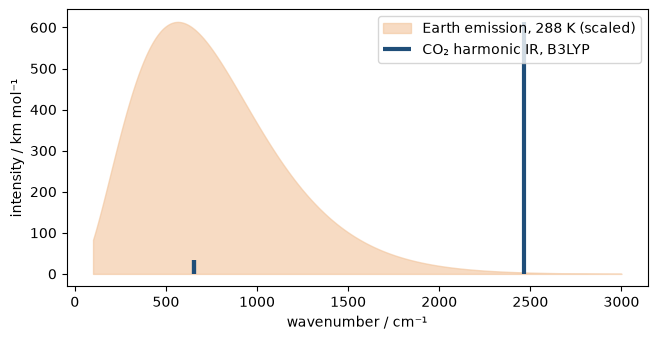

In [19]:
T = 288                                         # K
nu = np.linspace(100, 3000, 2901)               # cm⁻¹, 1 cm⁻¹ apart
x = nu / lk.EV_TO_CM1 / (lk.KB_EV * T)
B = nu**3 / np.expm1(x)
nu_peak = nu[np.argmax(B)]
print(f"Earth's emission (288 K) peaks at {nu_peak:.0f} cm⁻¹ = {1e4 / nu_peak:.1f} µm")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.fill_between(nu, B / B.max() * A.max(), color="#f2c49b", alpha=0.6, label="Earth emission, 288 K (scaled)")
ax.vlines(wn, 0, A, color="#1f4e79", lw=3, label="CO₂ harmonic IR, B3LYP")
ax.set_xlabel("wavenumber / cm⁻¹"); ax.set_ylabel("intensity / km mol⁻¹"); ax.legend()
plt.show()

In [20]:
lab.check('5.1')

### <font color=blue> **Question 5.2 Discussion.** </font>
<font color=green>

The bend at 667 cm⁻¹ (15 µm) sits near the peak of the Earth's thermal emission. Explain in two or three sentences why this
one vibration matters so much for climate, and why ν₃, though about ten times stronger, matters less.
</font>

---

**Sample answer (instructor version).** The Earth's 288 K emission peaks near 560 cm⁻¹, so the bend absorbs where the surface radiates most; CO₂ in the atmosphere absorbs that outgoing radiation and re-emits part of it back down, warming the surface. The band centre is already saturated, so added CO₂ mainly widens the band (the logarithmic dependence of forcing on concentration). ν₃ at 2349 cm⁻¹ lies far out in the tail of the 288 K curve, where very little energy is emitted, so its large intensity has little effect on the Earth's energy balance.

---

In [21]:
lab.check('5.2d')

## 6. Save the Results for Labs 5 and 6
**Just run the cell below.** It saves the geometry, modes, wavenumbers and intensities to `comp_chem/results/`.

In [22]:
# Just run this cell: save for Labs 5 and 6
np.savez(lk.results_path("co2_harmonic.npz"), symbols=np.array(symbols), X0=X0, wn=wn, disp=disp, modes=modes,
         intensity=A, masses=masses)
print("saved results/co2_harmonic.npz")

saved results/co2_harmonic.npz


### 📋 Summary of your results
**Just run the cell below.**

In [23]:
# Just run this cell: summary table
summary = Table().with_columns(
    'Mode', ['bend ν₂ (x)', 'bend ν₂ (y)', 'symmetric stretch ν₁', 'asymmetric stretch ν₃'],
    'B3LYP ν̃ (cm⁻¹)', [round(w, 1) for w in wn],
    'IR intensity (km/mol)', [round(a, 1) for a in A],
    'Experiment ν̃ (cm⁻¹)', [667.4, 667.4, '≈1333 (Raman)', 2349.1],
    'Experiment intensity (km/mol)', [24, 24, 0, 548])
summary.show()
print(f"r_e = {r_e:.4f} Å (expt 1.1600);  H[Cz, Cz]: analytic {H[5, 5]:.2f}, finite difference {fd:.2f} eV/Å²;  "
      f"Earth emission peak {nu_peak:.0f} cm⁻¹")

Mode,B3LYP ν̃ (cm⁻¹),IR intensity (km/mol),Experiment ν̃ (cm⁻¹),Experiment intensity (km/mol)
bend ν₂ (x),653.7,32.9,667.4,24
bend ν₂ (y),653.7,32.9,667.4,24
symmetric stretch ν₁,1389,0,≈1333 (Raman),0
asymmetric stretch ν₃,2466.9,613.5,2349.1,548


r_e = 1.1631 Å (expt 1.1600);  H[Cz, Cz]: analytic 195.29, finite difference 196.18 eV/Å²;  Earth emission peak 565 cm⁻¹


### 📝 Quick Check — Normal Modes
Test what you've learned. This is just for practice — answer as many times as you like, it isn't recorded.

In [24]:
with open("questionsComp04.json", "r") as f:
    display_quiz(json.load(f), shuffle_answers=True)

[quiz stand-in] 5 questions loaded


---
## 7. Conclusions

### <font color=blue> **Question 7. Conclusions.** </font>
<div style="border:2px solid #1f4e79; border-radius:8px; padding:10px 14px; background:#f3f7fb; color:#1a1a1a;">

Write the **Conclusions** of this lab in the cell below (one or two paragraphs, about 150–300 words), using **your own numbers**
from the summary table. Address:

1. How well harmonic B3LYP/def2-SVP reproduces the observed frequencies and intensities, and which errors are largest.
2. The symmetry argument for which modes are IR-active.
3. Why CO₂ is a greenhouse gas and O₂ and N₂ are not.
4. One limitation of the harmonic picture that Labs 5 and 6 will remove.
</div>

---

**Sample answer (instructor version).** Harmonic B3LYP/def2-SVP gives r_e = 1.163 Å (expt 1.160 Å) and vibrations at 654 (bend, ×2), 1389 and 2467 cm⁻¹; the bend is within 2 % of the observed 667 cm⁻¹, while the asymmetric stretch is 5 % above 2349 cm⁻¹, partly because the harmonic approximation ignores anharmonicity and partly because of the functional and the small basis. The intensities (2 × 33, 0 and 614 km/mol) have the observed pattern and are within about 30 % of experiment. The pattern follows from symmetry: the symmetric stretch keeps the inversion centre and has no dipole at any instant, while the bend and asymmetric stretch break it. O₂ and N₂ have only a symmetric stretch, so they cannot absorb infrared light; CO₂ can, and its bend lies under the peak of the Earth's thermal emission near 560 cm⁻¹, which is why it is a greenhouse gas. The harmonic picture is exact only for infinitesimal vibrations: it has no anharmonicity, no coupling between modes and no rotation, all of which shape the real spectrum. Labs 5 and 6 remove these limits with a machine-learned surface and molecular dynamics.

---

## 8. Reflection

### <font color=blue> **Question 8.** </font>
At the end of each lab, please include a reflection.
* How did this lab go? Was it clear what each calculation was doing?
* Which part of the Python was new to you, and which part was most useful?
* Did you use the hints? Which questions needed them?
* Were there questions you found especially challenging that you would like your instructor to review in class?
* How long did the lab take you to complete?

**Use the markdown cell below this one and write your reflection on this lab.**

---

**Sample answer (instructor version).** (Instructor version: students write their reflection here.) Watching the modes made the symmetry argument clear.

---

#### Save notebook before check
This cell checks your **Abstract** (at the top of the notebook), your **Conclusions** and your **Reflection**.

In [25]:
lab.check('abstract')
lab.check('7c')
lab.check('8d')

## 📚 References
1. Q. Sun et al., "Recent developments in the PySCF program package," *J. Chem. Phys.* **153**, 024109 (2020), [doi:10.1063/5.0006074](https://doi.org/10.1063/5.0006074).
2. P. Atkins, J. de Paula and J. Keeler, *Atkins' Physical Chemistry*, 11th ed., Oxford University Press (2018): Topic 7A (black-body radiation), Topic 11D (vibrational spectroscopy of polyatomic molecules), Topic 11E (symmetry analysis of vibrational spectra).
3. D. A. McQuarrie and J. D. Simon, *Physical Chemistry: A Molecular Approach*, University Science Books (1997), Ch. 13 (normal coordinates) and Ch. 12 (group theory).
4. E. B. Wilson, J. C. Decius and P. C. Cross, *Molecular Vibrations*, McGraw-Hill (1955; Dover reprint 1980).
5. A. D. Becke, "Density-functional thermochemistry. III. The role of exact exchange," *J. Chem. Phys.* **98**, 5648 (1993), [doi:10.1063/1.464913](https://doi.org/10.1063/1.464913).
6. F. Weigend and R. Ahlrichs, "Balanced basis sets of split valence, triple zeta valence and quadruple zeta valence quality for H to Rn," *Phys. Chem. Chem. Phys.* **7**, 3297 (2005), [doi:10.1039/b508541a](https://doi.org/10.1039/b508541a).
7. NIST Chemistry WebBook, "Carbon dioxide": [vibrational and electronic energy levels](https://webbook.nist.gov/cgi/cbook.cgi?ID=C124389&Mask=800).
8. W. D. Collins et al., "Radiative forcing by well-mixed greenhouse gases," *J. Geophys. Res.* **111**, D14317 (2006), [doi:10.1029/2005JD006713](https://doi.org/10.1029/2005JD006713).

## 🏁 Final Step — Check, Submit, Then Upload to Canvas

Follow these steps **in order**:

1. 💾 **Save** the notebook (Ctrl/Cmd + S): the written-answer checks and the submission read the *saved* file.
2. ✅ **Run the cell below** to see your score: one row per question, with the number of attempts. Any question still marked ❌ or
   *not checked*: go back, fix it, and run its check again.
3. 📨 **Click Submit Lab.** This records your score, your abstract, your conclusions and your discussion answers under your
   JupyterHub username. You can submit again after making changes; the latest submission counts.
4. 📤 **Make a PDF and upload it to Canvas.** Export an HTML copy ([instructions](https://laserchemist.github.io/data/submission-instructions/export-html)), open it in your browser, and use **Print → Save as PDF**. Check that your plots, tables and written answers all appear in the PDF, then upload it to this lab's Canvas assignment.

In [26]:
# Your score for this lab, and the Submit button
lab.score()
lab.submit(name, lab_id='Comp04')